<a href="https://colab.research.google.com/github/yatri21/Connect_Four/blob/main/Connect_Four_AI(p).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Connect Four AI
**Minimax, Alpha-Beta Pruning and an optimised search engine** · ECSCT24301 – Foundation of AI · Adani University
Team: Name – Enrollment No. · Name – Enrollment No. · Name – Enrollment No.

**About the project.** Connect Four is a two-player game on a 7 × 6 board: players take turns dropping discs into a column, and the first to connect four discs in a row (horizontally, vertically or diagonally) wins. This notebook builds an AI that plays the game by *searching ahead*: it tries possible moves, imagines the opponent's best replies, and picks the move with the best outcome.

**How the notebook is organised**
1. **Game and AI** – the board, the heuristic and the four AI levels.
2. **Results** – how much work each algorithm does, and how well each one plays.
3. **Play** – an interactive game against the AI.

Run **Runtime → Run all** (about 2 minutes), then scroll to the bottom to play.

## 1. Game and AI

**How the board is stored.** The board is kept as *bitboards*: whole-board integers in which every bit is one cell (1 = a disc is there). One integer holds all discs and another holds the discs of the player to move. Checking for four in a row or finding threats then takes a few bit-shift operations instead of loops over cells, which makes the search many times faster.

**The four AI levels**

| AI | How it works |
|---|---|
| **Random** | Picks any legal column. Used as a baseline to compare against. |
| **Minimax** | Looks `depth` moves ahead, assuming the opponent always replies with their best move. Our turn picks the highest score, the opponent's turn picks the lowest. |
| **Alpha-Beta** | Gives exactly the same decisions as Minimax but skips branches that cannot change the result, so it searches far fewer positions. Trying the centre columns first makes the pruning more effective. |
| **Advanced engine** | Alpha-Beta plus four improvements: **iterative deepening** (search 1 move ahead, then 2, then 3… until the time budget ends, so it always has a move ready), a **transposition table** (remembers positions already analysed), **threat-based move ordering** (tries the most promising moves first), and **forced-move detection** (takes an immediate win, blocks an opponent win, never plays a move that hands the opponent a win). |

**The heuristic.** The search cannot look all the way to the end of the game, so at its depth limit it *estimates* how good a position is: +8 for every empty cell where we could complete four (a threat), −8 for each of the opponent's threats, plus a small bonus for discs in the centre columns, which take part in the most winning lines. A positive score favours the player to move.

**Key terms:** *depth* = how many moves ahead the search looks · *positions searched* = how many board positions were examined (a measure of work) · *pruning* = skipping branches that cannot matter.

In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, random, time, math
import ipywidgets as widgets
from IPython.display import display, HTML, clear_output
random.seed(42)

# =====================================================================
#  BOARD REPRESENTATION (bitboards)
#  The 6x7 board is stored as integers whose bits are board cells.
#  Each column uses 7 bits (6 cells + 1 spare "sentinel" bit on top),
#  so bit shifts never wrap from one column into the next.
# =====================================================================
H, W = 6, 7                      # board height / width
H1 = H + 1                       # bits per column in the bitboard
WIN, INF = 1_000_000, 10**9      # WIN = score of a proven win; INF = "infinity" for alpha-beta
BOTTOM = sum(1 << (c * H1) for c in range(W))        # bit of the bottom cell of every column
BOARD = BOTTOM * ((1 << H) - 1)                      # bits of all 42 playable cells
COL_ORDER = [3, 2, 4, 1, 5, 0, 6]                    # try centre columns first (they are usually stronger)
COLMASK = [((1 << H) - 1) << (c * H1) for c in range(W)]   # bits belonging to each column
EMPTY, HUMAN, AI = 0, 1, 2                           # cell codes used for display

try:    popcount = int.bit_count                     # number of 1-bits in an integer
except AttributeError: popcount = lambda x: bin(x).count('1')

# A search state is (cur, mask, n):
#   mask = every disc on the board, cur = discs of the player TO MOVE, n = discs played so far.
#   The opponent's discs are therefore (cur ^ mask).

# =====================================================================
#  BITBOARD HELPERS
# =====================================================================
def alignment(p):
    """True if the discs in bitboard p contain four in a row (4 directions, using shifts)."""
    m = p & (p >> H1)
    if m & (m >> (2 * H1)): return True              # horizontal
    m = p & (p >> H)
    if m & (m >> (2 * H)): return True               # diagonal \\
    m = p & (p >> (H + 2))
    if m & (m >> (2 * (H + 2))): return True         # diagonal /
    m = p & (p >> 1)
    return bool(m & (m >> 2))                        # vertical

def win_spots(p, mask):
    """Empty cells that would complete four in a row for the discs in p (i.e. that player's threats)."""
    r = (p << 1) & (p << 2) & (p << 3)               # vertical threes
    for s in (H1, H, H + 2):                         # horizontal and both diagonals
        q = (p << s) & (p << 2 * s)
        r |= q & (p << 3 * s); r |= q & (p >> s)
        q = (p >> s) & (p >> 2 * s)
        r |= q & (p << s); r |= q & (p >> 3 * s)
    return r & (BOARD ^ mask)                        # keep only cells that are still empty

def playable(mask):
    """One bit per column: the lowest empty cell, i.e. where a disc would land."""
    return (mask + BOTTOM) & BOARD

# =====================================================================
#  HEURISTIC (used when the search reaches its depth limit)
# =====================================================================
def evaluate(cur, mask):
    """Score a position for the player to move. Positive = good for them.
       +8 per threat cell they own, -8 per threat cell the opponent owns,
       +3 per disc in the centre column, +1 per disc in the two neighbouring columns."""
    opp = cur ^ mask
    s = 8 * (popcount(win_spots(cur, mask)) - popcount(win_spots(opp, mask)))
    s += 3 * (popcount(cur & COLMASK[3]) - popcount(opp & COLMASK[3]))
    side = COLMASK[2] | COLMASK[4]
    s += popcount(cur & side) - popcount(opp & side)
    return s

class Stats:
    """Counters reported after every search."""
    def __init__(self): self.nodes = 0; self.cutoffs = 0; self.time = 0.0; self.depth = 0; self.tt_hits = 0

class Timeout(Exception): pass                       # raised when the time budget runs out

# =====================================================================
#  ALGORITHM 1: MINIMAX
#  Maximising player = the AI (root player), minimising player = the opponent.
#  Values are always from the ROOT player's point of view.
# =====================================================================
def minimax(cur, mask, n, depth, maximizing, st):
    st.nodes += 1
    if n == H * W: return 0                          # board full -> draw
    if depth == 0:                                   # depth limit -> estimate with the heuristic
        e = evaluate(cur, mask); return e if maximizing else -e
    best = -INF if maximizing else INF
    for c in range(W):
        bit = playable(mask) & COLMASK[c]
        if not bit: continue                         # column full
        if alignment(cur | bit):                     # this move wins immediately
            st.nodes += 1; v = (WIN + depth) if maximizing else -(WIN + depth)   # +depth: prefer faster wins
        else:
            v = minimax(cur ^ mask, mask | bit, n + 1, depth - 1, not maximizing, st)
        best = max(best, v) if maximizing else min(best, v)
    return best

# =====================================================================
#  ALGORITHM 2: MINIMAX + ALPHA-BETA PRUNING
#  alpha = best score the maximiser can already guarantee, beta = best for the minimiser.
#  When alpha >= beta the remaining moves cannot change the outcome, so they are skipped.
# =====================================================================
def alphabeta(cur, mask, n, depth, alpha, beta, maximizing, st):
    st.nodes += 1
    if n == H * W: return 0
    if depth == 0:
        e = evaluate(cur, mask); return e if maximizing else -e
    best = -INF if maximizing else INF
    for c in COL_ORDER:                              # centre-first ordering makes pruning more effective
        bit = playable(mask) & COLMASK[c]
        if not bit: continue
        if alignment(cur | bit):
            st.nodes += 1; v = (WIN + depth) if maximizing else -(WIN + depth)
        else:
            v = alphabeta(cur ^ mask, mask | bit, n + 1, depth - 1, alpha, beta, not maximizing, st)
        if maximizing: best = max(best, v); alpha = max(alpha, best)
        else:          best = min(best, v); beta = min(beta, best)
        if alpha >= beta: st.cutoffs += 1; break     # cut-off: prune the remaining moves
    return best

# =====================================================================
#  ALGORITHM 3: ADVANCED ENGINE
#  Alpha-Beta written in "negamax" form (one function for both players: my score = -opponent's score),
#  plus: forced-move detection, transposition table, move ordering, iterative deepening, time control.
# =====================================================================
class Engine:
    def __init__(self): self.tt = {}                 # transposition table: position -> what we learned about it

    def negamax(self, cur, mask, n, depth, alpha, beta, st):
        st.nodes += 1
        if (st.nodes & 2047) == 0 and time.perf_counter() > self.deadline: raise Timeout
        if n == H * W: return 0                                              # draw
        poss = playable(mask)

        # --- forced-move detection (cheap tactics, no search needed) ---
        if win_spots(cur, mask) & poss: return WIN + depth                   # I can win right now
        opp_win = win_spots(cur ^ mask, mask)
        forced = poss & opp_win                                              # cells where the opponent would win next
        if forced:
            if forced & (forced - 1): return -(WIN + depth - 1)              # two threats at once: I cannot stop both
            poss = forced                                                    # exactly one threat: I must block it
        poss &= ~(opp_win >> 1)                                              # never play directly below an opponent winning cell
        if not poss: return -(WIN + max(depth - 2, 0))                       # every move loses
        if depth == 0: return evaluate(cur, mask)

        # --- transposition table lookup: reuse earlier results for the same position ---
        key = cur + mask; a0 = alpha; best_mv = 0
        e = self.tt.get(key)
        if e:
            d, flag, val, best_mv = e                                        # flag: 0 exact, 1 lower bound, 2 upper bound
            if d >= depth:
                st.tt_hits += 1
                if flag == 0: return val
                if flag == 1: alpha = max(alpha, val)
                else: beta = min(beta, val)
                if alpha >= beta: return val

        # --- move ordering: best move from the table first, then moves that create the most threats ---
        moves = []
        for i, c in enumerate(COL_ORDER):
            bit = poss & COLMASK[c]
            if bit:
                pri = popcount(win_spots(cur | bit, mask | bit)) * 10 - i + (100 if bit == best_mv else 0)
                moves.append((pri, bit))
        moves.sort(reverse=True)                                             # good ordering = many more alpha-beta cut-offs

        best = -INF
        for _, bit in moves:
            v = -self.negamax(cur ^ mask, mask | bit, n + 1, depth - 1, -beta, -alpha, st)
            if v > best: best = v; best_mv = bit
            if best > alpha: alpha = best
            if alpha >= beta: st.cutoffs += 1; break
        self.tt[key] = (depth, 0 if a0 < best < beta else (1 if best >= beta else 2), best, best_mv)
        return best

    def choose(self, cur, mask, n, time_limit=1.0, max_depth=42):
        """Iterative deepening: search depth 1, 2, 3, ... until the time budget ends, always keeping the
           result of the last COMPLETED depth. Returns (column, {column: score}, Stats).
           Scores of columns other than the chosen one are upper bounds ('no better than ...')."""
        st = Stats(); t0 = time.perf_counter(); self.deadline = t0 + time_limit
        if len(self.tt) > 3_000_000: self.tt.clear()                         # keep memory bounded
        poss = playable(mask)
        for c in range(W):                                                   # 1) take an immediate win
            if poss & COLMASK[c] and alignment(cur | (poss & COLMASK[c])):
                st.time = time.perf_counter() - t0; return c, {c: WIN}, st
        if n == 0:                                                           # 2) opening book: start in the centre
            st.time = time.perf_counter() - t0; return 3, {3: 0}, st
        legal = [c for c in COL_ORDER if poss & COLMASK[c]]
        best_col, scores = legal[0], {}
        opp_win = win_spots(cur ^ mask, mask)
        block = [c for c in legal if poss & COLMASK[c] & opp_win]
        if len(block) == 1: best_col = block[0]                              # 3) fallback = forced block
        try:
            for depth in range(1, min(max_depth, H * W - n) + 1):            # 4) iterative deepening
                alpha, it_best, it_scores = -INF, None, {}
                order = sorted(legal, key=lambda c: (c != best_col))         # previous best move first
                for c in order:
                    bit = poss & COLMASK[c]
                    v = -self.negamax(cur ^ mask, mask | bit, n + 1, depth - 1, -INF, -alpha, st)
                    it_scores[c] = v
                    if v > alpha: alpha, it_best = v, c
                best_col, scores, st.depth = it_best, it_scores, depth
                if abs(alpha) >= WIN // 2: break                             # proven win/loss: no need to search deeper
        except Timeout: pass                                                 # out of time: keep last completed depth
        st.time = time.perf_counter() - t0
        return best_col, scores, st

ENGINE = Engine()

# =====================================================================
#  GAME STATE AND MOVE SELECTION
# =====================================================================
class Position:
    """A game in progress: bitboards for the search plus a plain grid for drawing the board."""
    def __init__(self):
        self.cur = self.mask = self.n = 0
        self.grid = np.zeros((H, W), dtype=np.int8); self.heights = [0] * W
    def copy(self):
        p = Position(); p.cur, p.mask, p.n = self.cur, self.mask, self.n
        p.grid = self.grid.copy(); p.heights = list(self.heights); return p
    def legal(self): return [c for c in range(W) if self.heights[c] < H]    # columns that are not full
    def play(self, col, piece):
        """Drop a disc (piece = HUMAN or AI) in a column; returns the row it landed in."""
        row = H - 1 - self.heights[col]; self.grid[row, col] = piece; self.heights[col] += 1
        self.cur ^= self.mask; self.mask |= self.mask + (1 << (col * H1)); self.n += 1
        return row
    def win_cells(self, r, c):
        """The four cells forming a line through (r, c), or None if the last disc did not win."""
        p = self.grid[r, c]
        for dr, dc in ((0, 1), (1, 0), (1, 1), (1, -1)):
            line = [(r, c)]
            for s in (1, -1):
                rr, cc = r + s * dr, c + s * dc
                while 0 <= rr < H and 0 <= cc < W and self.grid[rr, cc] == p:
                    line.append((rr, cc)); rr += s * dr; cc += s * dc
            if len(line) >= 4: return line
        return None
    def is_full(self): return self.n == H * W

def choose_move(pos, algo='advanced', depth=4, time_limit=1.0):
    """Pick a move with the chosen algorithm: random | minimax | alphabeta | advanced.
       Returns (column, {column: score}, Stats)."""
    st = Stats(); t0 = time.perf_counter()
    if algo == 'random':
        st.time = time.perf_counter() - t0; return random.choice(pos.legal()), {}, st
    if algo == 'advanced': return ENGINE.choose(pos.cur, pos.mask, pos.n, time_limit)
    scores = {}; poss = playable(pos.mask)
    for c in COL_ORDER:                              # score every possible first move, then take the best
        bit = poss & COLMASK[c]
        if not bit: continue
        if alignment(pos.cur | bit): st.nodes += 1; s = WIN + depth
        elif algo == 'minimax': s = minimax(pos.cur ^ pos.mask, pos.mask | bit, pos.n + 1, depth - 1, False, st)
        else: s = alphabeta(pos.cur ^ pos.mask, pos.mask | bit, pos.n + 1, depth - 1, -INF, INF, False, st)
        scores[c] = s
    st.time = time.perf_counter() - t0; st.depth = depth
    best = max(scores.values())
    return random.choice([c for c, s in scores.items() if s == best]), scores, st     # random tie-break

def play_game(cfg1, cfg2):
    """Play one full game between two AI settings (dicts for choose_move). Player 1 moves first.
       Returns 1, 2, or 0 for a draw."""
    pos, turn, cfgs = Position(), 1, {1: cfg1, 2: cfg2}
    while True:
        col, _, _ = choose_move(pos, **cfgs[turn]); r = pos.play(col, turn)
        if pos.win_cells(r, col): return turn
        if pos.is_full(): return 0
        turn = 3 - turn

## 2. Results
### 2.1 How much work does each algorithm do?
We take 6 random mid-game positions (with no forced win or loss, so every algorithm has to search properly) and measure, on average, how many positions each algorithm examines and how long it takes at increasing depth. Minimax and Alpha-Beta get a fixed depth; the Advanced engine gets a time budget and reports how deep it managed to search.

**How to read the output:** the table lists *positions searched* and *time per move*; the left chart shows how the work grows with depth (log scale, so a straight line means exponential growth); the right chart shows how many moves ahead each algorithm can look within about one second.

,Algorithm,Depth,Positions searched,Time/move (s)
0,Minimax,1.0,7,0.000
1,Minimax,2.0,56,0.001
2,Minimax,3.0,391,0.005
3,Minimax,4.0,2717,0.044
4,Minimax,5.0,18417,0.492
5,Minimax,6.0,124910,1.357
6,Alpha-Beta,1.0,7,0.000
7,Alpha-Beta,2.0,56,0.000
8,Alpha-Beta,3.0,174,0.001
9,Alpha-Beta,4.0,795,0.005


Positions saved by Alpha-Beta vs Minimax at each depth (%): {1.0: 0.0, 2.0: 0.0, 3.0: 55.5, 4.0: 70.7, 5.0: 88.6, 6.0: 92.1}


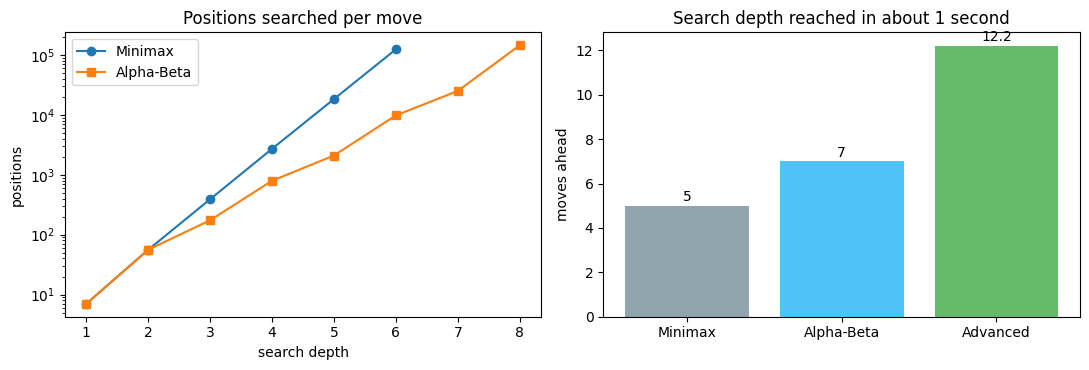

In [ ]:
def random_position(plies):
    """Play `plies` random moves (restarting if someone wins early) to get a realistic mid-game position."""
    while True:
        p, t, ok = Position(), 1, True
        for _ in range(plies):
            c = random.choice(p.legal()); r = p.play(c, t)
            if p.win_cells(r, c): ok = False; break
            t = 3 - t
        if ok: return p

# quiet mid-game positions (no forced win/loss), so every algorithm has to search properly
positions = []
while len(positions) < 6:
    p = random_position(random.randint(6, 12))
    if abs(max(choose_move(p, 'advanced', time_limit=0.2)[1].values())) < WIN // 2: positions.append(p)

rows = []
for algo, name, max_d in [('minimax', 'Minimax', 9), ('alphabeta', 'Alpha-Beta', 16)]:
    for d in range(1, max_d + 1):
        res = [choose_move(p, algo, d)[2] for p in positions]
        t = np.mean([s.time for s in res])
        rows.append({'Algorithm': name, 'Depth': d, 'Positions searched': int(np.mean([s.nodes for s in res])), 'Time/move (s)': round(t, 3)})
        if t > 1.0: break                                   # stop once a move takes more than 1 s
for tl in (0.5, 1.0):
    res = [choose_move(p, 'advanced', time_limit=tl)[2] for p in positions]
    rows.append({'Algorithm': f'Advanced ({tl} s budget)', 'Depth': round(np.mean([s.depth for s in res]), 1),
                 'Positions searched': int(np.mean([s.nodes for s in res])), 'Time/move (s)': round(np.mean([s.time for s in res]), 3)})
cost = pd.DataFrame(rows); display(cost)

mm, ab = cost[cost.Algorithm == 'Minimax'], cost[cost.Algorithm == 'Alpha-Beta']
common = mm.Depth[mm.Depth.isin(ab.Depth)]
saved = 100 * (1 - ab.set_index('Depth')['Positions searched'].loc[common] / mm.set_index('Depth')['Positions searched'].loc[common])
print('Positions saved by Alpha-Beta vs Minimax at each depth (%):', saved.round(1).to_dict())

reach = {'Minimax': int(mm[mm['Time/move (s)'] <= 1].Depth.max()), 'Alpha-Beta': int(ab[ab['Time/move (s)'] <= 1].Depth.max()),
         'Advanced': cost[cost.Algorithm.str.startswith('Advanced (1.0')].Depth.iloc[0]}
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(mm.Depth, mm['Positions searched'], 'o-', label='Minimax'); ax[0].plot(ab.Depth, ab['Positions searched'], 's-', label='Alpha-Beta')
ax[0].set(title='Positions searched per move', xlabel='search depth', ylabel='positions', yscale='log'); ax[0].legend()
ax[1].bar(reach.keys(), reach.values(), color=['#90a4ae', '#4fc3f7', '#66bb6a']); ax[1].set(title='Search depth reached in about 1 second', ylabel='moves ahead')
for i, v in enumerate(reach.values()): ax[1].text(i, v + .2, f'{v:g}', ha='center')
plt.tight_layout(); plt.show()

**What this shows.** The number of positions grows roughly 7× with every extra move of depth for plain Minimax. Alpha-Beta returns the same decisions while examining a small fraction of those positions, and the saving grows with depth. The Advanced engine adds ordering, memory and tactics on top, so in the same one second it looks several moves deeper than plain Alpha-Beta.

### 2.2 Playing strength
Speed only matters if it turns into better play, so we let the Advanced engine (0.3 seconds per move) play full games against the other AIs. Games alternate who moves first. Each result reads **won – drawn – lost** from the Advanced engine's point of view. A small number of games is used to keep the notebook quick, so exact scores can vary slightly between runs.

In [ ]:
def match(cfg_a, cfg_b, games=6):
    """Play `games` games between A and B, swapping who moves first, and count A's wins, losses and draws."""
    w = [0, 0, 0]
    for i in range(games):
        if i % 2 == 0: r = play_game(cfg_a, cfg_b); a = 1
        else:          r = play_game(cfg_b, cfg_a); a = 2
        w[2 if r == 0 else 0 if r == a else 1] += 1
    return f'{w[0]} - {w[2]} - {w[1]}'

adv = dict(algo='advanced', time_limit=0.3)
rows = [{'Advanced engine (0.3 s/move) vs': name, 'Won - Drawn - Lost': match(adv, cfg, games)} for name, cfg, games in [
    ('Random', dict(algo='random'), 4),
    ('Minimax, depth 3', dict(algo='minimax', depth=3), 6),
    ('Alpha-Beta, depth 4', dict(algo='alphabeta', depth=4), 6),
    ('Alpha-Beta, depth 6', dict(algo='alphabeta', depth=6), 6)]]
display(pd.DataFrame(rows))

,Advanced engine (0.3 s/move) vs,Won - Drawn - Lost
0,Random,4 - 0 - 0
1,"Minimax, depth 3",6 - 0 - 0
2,"Alpha-Beta, depth 4",5 - 1 - 0
3,"Alpha-Beta, depth 6",5 - 1 - 0


## 3. Play against the AI
Choose a difficulty and press **New Game**, then click a column number to drop your disc (🔴 you, 🟡 AI). Press **Hint** to see what the engine would play for you.

| Level | AI used |
|---|---|
| Easy | Random |
| Medium | Alpha-Beta, depth 3 |
| Hard | Advanced engine, 0.5 s per move |
| Expert | Advanced engine, 3 s per move |

**Reading the AI's analysis.** After each AI move you see how many moves ahead it looked, how many positions it searched, and a table with one score per column. A higher score is better for the AI; *win* / *loss* means a forced result was found. The chosen column is green; for the Advanced engine the other columns show `≤`, meaning "no better than the chosen move" (the search stops looking at a move as soon as it is proven not to beat the best one).

In [ ]:
# Difficulty levels: each one is just a different setting for choose_move()
COLORS = {EMPTY: '#eceff1', HUMAN: '#e53935', AI: '#fdd835'}
LEVELS = {'Easy': dict(algo='random'), 'Medium': dict(algo='alphabeta', depth=3),
          'Hard': dict(algo='advanced', time_limit=0.5), 'Expert': dict(algo='advanced', time_limit=3.0)}

def board_html(grid, win=None, last=None):
    """Draw the board as HTML: blue frame, round cells; winning discs get a green ring, the last move a black ring."""
    win = win or []
    h = '<div style="background:#1565c0;padding:10px;border-radius:12px;display:inline-block">'
    for r in range(H):
        h += '<div style="display:flex">'
        for c in range(W):
            border = '4px solid #00c853' if (r, c) in win else '3px solid #000' if last == (r, c) else '3px solid #0d47a1'
            h += f'<div style="width:42px;height:42px;margin:3px;border-radius:50%;background:{COLORS[int(grid[r][c])]};border:{border}"></div>'
        h += '</div>'
    return h + '</div>'

def show(s, bound=False):
    t = 'win' if s > WIN // 2 else 'loss' if s < -WIN // 2 else s
    return f'≤ {t}' if bound and isinstance(t, int) else t

class Game:
    """The interactive game: dropdowns and buttons (ipywidgets) around a Position and choose_move()."""
    def __init__(self):
        self.level = widgets.Dropdown(options=list(LEVELS), value='Hard', description='Difficulty')
        self.first = widgets.Dropdown(options=['You', 'AI'], value='You', description='First move')
        self.new = widgets.Button(description='New Game', button_style='success', icon='refresh')
        self.hint = widgets.Button(description='Hint', icon='lightbulb-o')
        self.new.on_click(lambda _: self.reset()); self.hint.on_click(lambda _: self.give_hint())
        self.buttons = [widgets.Button(description=str(c + 1), layout=widgets.Layout(width='48px', margin='0')) for c in range(W)]
        for c, b in enumerate(self.buttons): b.on_click(lambda _, c=c: self.human_move(c))
        self.out = widgets.Output()
        display(widgets.VBox([widgets.HBox([self.level, self.first, self.new, self.hint]),
                              widgets.HBox(self.buttons, layout=widgets.Layout(padding='8px 0 0 10px')), self.out]))
        self.reset()

    def reset(self):
        self.pos = Position(); self.over = False; self.last = None; self.win = []
        self.msg, self.info = 'Your turn.', ''
        if self.first.value == 'AI': self.ai_move()
        else: self.render()

    def render(self):
        with self.out:
            clear_output(wait=True)
            display(HTML(board_html(self.pos.grid, self.win, self.last) + f'<h3 style="margin:8px 0">{self.msg}</h3>' + self.info))
        legal = self.pos.legal()
        for c, b in enumerate(self.buttons): b.disabled = self.over or c not in legal
        self.hint.disabled = self.over

    def finish(self, who, r, c):
        cells = self.pos.win_cells(r, c)
        if cells: self.win = cells; self.msg = '🎉 You win!' if who == HUMAN else '🤖 The AI wins!'; self.over = True
        elif self.pos.is_full(): self.msg = "It's a draw."; self.over = True
        return self.over

    def human_move(self, c):
        if self.over: return
        r = self.pos.play(c, HUMAN); self.last = (r, c); self.info = ''
        if self.finish(HUMAN, r, c): return self.render()
        self.msg = 'AI is thinking...'; self.render(); self.ai_move()

    def give_hint(self):
        if self.over: return
        col, _, _ = choose_move(self.pos, 'advanced', time_limit=1.0)
        self.info = f'<p>💡 Suggested move: <b>column {col + 1}</b></p>'; self.render()

    def ai_move(self):
        cfg = LEVELS[self.level.value]
        col, scores, st = choose_move(self.pos, **cfg)
        r = self.pos.play(col, AI); self.last = (r, col)
        if scores:
            bound = cfg['algo'] == 'advanced'
            head = ''.join(f'<th style="padding:2px 10px">{c + 1}</th>' for c in range(W))
            body = ''.join(f'<td style="padding:2px 10px;text-align:center;{"background:#c8e6c9;font-weight:bold;color:#000" if c == col else ""}">'
                           f'{show(scores[c], bound and c != col) if c in scores else "–"}</td>' for c in range(W))
            depth = f'looked {st.depth} moves ahead · ' if st.depth else ''
            self.info = (f'<p>AI played column <b>{col + 1}</b> · {depth}<b>{st.nodes:,}</b> positions searched · {st.time * 1000:.0f} ms</p>'
                         f'<table border="1" style="border-collapse:collapse"><tr><th>Column</th>{head}</tr><tr><th>Score</th>{body}</tr></table>')
        else: self.info = f'<p>AI played column {col + 1}.</p>'
        if not self.finish(AI, r, col): self.msg = 'Your turn.'
        self.render()

game = Game()

## Summary
* **Minimax** finds good moves by assuming the opponent replies optimally, but its work grows exponentially with depth.
* **Alpha-Beta pruning** keeps the same decisions while skipping most of the tree, so it can search much deeper in the same time.
* **Iterative deepening, a transposition table, move ordering and forced-move detection** make the Advanced engine the strongest level: it looks furthest ahead and wins most games against the simpler searches.
* **Limitations:** the heuristic is only an estimate, so depth-limited play can still misjudge some positions; solving Connect Four perfectly from the start needs far more computation than a pure-Python notebook offers.
* **Possible extensions:** a bigger opening book, a learned evaluation function, Monte Carlo Tree Search, and exact solving of the late game.